In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment


PROJECT_DIR = Path("/Users/hyuna/OpenNeuro/ds007116")
DERIVED_DIR = PROJECT_DIR / "derived"
RESULTS_DIR = PROJECT_DIR / "results" / "summary_tables"
FIGURE_DIR = PROJECT_DIR / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


FEATURES = [
    "eswan_adhd_inattention_total",
    "eswan_adhd_hyperactivity_impulsivity_total",
    "bissc_total",
    "bas_total",
    "im_average",
    "em_average",
    "cnb_cptnl_total_sen",
    "cnb_cptnl_total_fp",
    "cnb_edisc_tot",
    "cnb_ddisc_tot",
    "cnb_rdisc_tot"
]


df = pd.read_csv(
    DERIVED_DIR / "clustering_input_z.csv"
)

print(df.shape)
print(df["session_id"].value_counts(dropna=False))

X = df[FEATURES].to_numpy(dtype=float)

assert X.shape == (92, 11)
assert np.isfinite(X).all()

print("X shape:", X.shape)

(92, 13)
session_id
ses-1    92
Name: count, dtype: int64
X shape: (92, 11)


In [3]:
reference_gmm = GaussianMixture(
    n_components=5,
    covariance_type="full",
    n_init=200,
    max_iter=1000,
    random_state=42
)

reference_labels = reference_gmm.fit_predict(X)

print("Reference cluster sizes:")
print(
    pd.Series(reference_labels)
    .value_counts()
    .sort_index()
)

print("BIC:", reference_gmm.bic(X))
print("AIC:", reference_gmm.aic(X))

Reference cluster sizes:
0     6
1    41
2     9
3     7
4    29
Name: count, dtype: int64
BIC: 2707.918527680773
AIC: 1726.9427712086965


In [4]:
# ============================================================
# 3. Bootstrap stability of the k=5 GMM
# ============================================================

N_BOOT = 500
rng = np.random.default_rng(42)

bootstrap_results = []
bootstrap_labels = []

n = X.shape[0]

for b in range(N_BOOT):

    # --------------------------------------------------------
    # 1) Bootstrap participants with replacement
    # --------------------------------------------------------
    boot_idx = rng.choice(
        n,
        size=n,
        replace=True
    )

    X_boot = X[boot_idx]

    # --------------------------------------------------------
    # 2) Fit the same k=5 GMM specification
    # --------------------------------------------------------
    gmm_boot = GaussianMixture(
        n_components=5,
        covariance_type="full",
        n_init=50,
        max_iter=1000,
        random_state=b
    )

    try:
        gmm_boot.fit(X_boot)

        # ----------------------------------------------------
        # 3) Apply bootstrap-fitted model to ORIGINAL N=92
        # ----------------------------------------------------
        labels_all = gmm_boot.predict(X)

        # Label permutation does not matter for ARI
        ari = adjusted_rand_score(
            reference_labels,
            labels_all
        )

        sizes = np.bincount(
            labels_all,
            minlength=5
        )

        bootstrap_results.append({
            "bootstrap": b,
            "ARI": ari,
            "converged": gmm_boot.converged_,
            "min_cluster_size": sizes.min(),
            "max_cluster_size": sizes.max()
        })

        bootstrap_labels.append(labels_all)

    except Exception as e:

        bootstrap_results.append({
            "bootstrap": b,
            "ARI": np.nan,
            "converged": False,
            "min_cluster_size": np.nan,
            "max_cluster_size": np.nan
        })

        bootstrap_labels.append(None)


bootstrap_results = pd.DataFrame(
    bootstrap_results
)

print("Completed:", len(bootstrap_results))
print(
    "Successful:",
    bootstrap_results["ARI"].notna().sum()
)

print(
    "Converged:",
    bootstrap_results["converged"].sum()
)

print()
print("ARI summary:")
print(
    bootstrap_results["ARI"].describe(
        percentiles=[.05, .25, .50, .75, .95]
    )
)

print()
print("Minimum predicted cluster size:")
print(
    bootstrap_results[
        "min_cluster_size"
    ].describe()
)

Completed: 500
Successful: 500
Converged: 500

ARI summary:
count    500.000000
mean       0.166308
std        0.085646
min       -0.024262
5%         0.039789
25%        0.100154
50%        0.158235
75%        0.221769
95%        0.310424
max        0.459772
Name: ARI, dtype: float64

Minimum predicted cluster size:
count    500.000000
mean       4.076000
std        1.371856
min        1.000000
25%        3.000000
50%        4.000000
75%        5.000000
max        8.000000
Name: min_cluster_size, dtype: float64


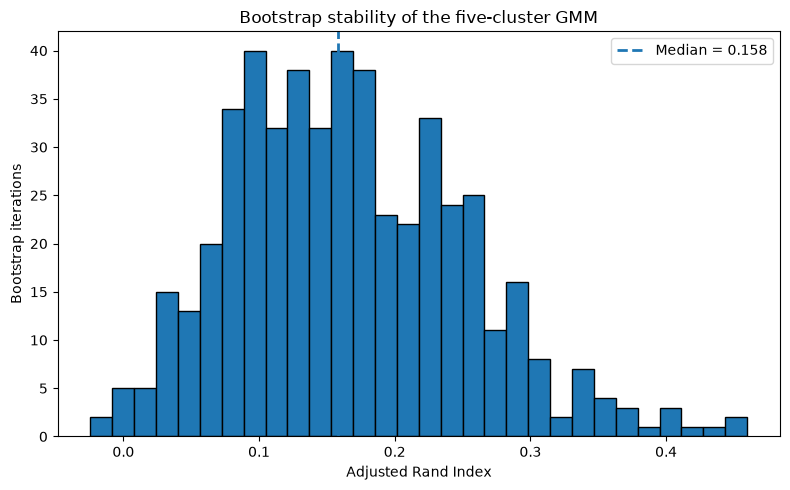

In [5]:
# ============================================================
# 4. ARI distribution
# ============================================================

valid_ari = bootstrap_results[
    "ARI"
].dropna()

plt.figure(figsize=(8, 5))

plt.hist(
    valid_ari,
    bins=30,
    edgecolor="black"
)

plt.axvline(
    valid_ari.median(),
    linestyle="--",
    linewidth=2,
    label=f"Median = {valid_ari.median():.3f}"
)

plt.xlabel("Adjusted Rand Index")
plt.ylabel("Bootstrap iterations")
plt.title(
    "Bootstrap stability of the five-cluster GMM"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "gmm_k5_bootstrap_ARI.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [6]:
# ============================================================
# 5. Match bootstrap clusters to reference clusters
# ============================================================

def match_to_reference(reference, candidate, k=5):

    contingency = np.zeros(
        (k, k),
        dtype=int
    )

    for r in range(k):
        for c in range(k):
            contingency[r, c] = np.sum(
                (reference == r) &
                (candidate == c)
            )

    # Maximize overlap
    row_ind, col_ind = linear_sum_assignment(
        -contingency
    )

    mapping = {
        candidate_cluster: reference_cluster
        for reference_cluster, candidate_cluster
        in zip(row_ind, col_ind)
    }

    matched = np.array([
        mapping[x]
        for x in candidate
    ])

    return matched


matched_bootstrap_labels = []

for labels in bootstrap_labels:

    if labels is None:
        matched_bootstrap_labels.append(None)
        continue

    matched = match_to_reference(
        reference_labels,
        labels,
        k=5
    )

    matched_bootstrap_labels.append(
        matched
    )

In [7]:
# ============================================================
# 6. Cluster-specific recovery
# ============================================================

recovery_rows = []

for b, matched in enumerate(
    matched_bootstrap_labels
):

    if matched is None:
        continue

    for cluster in range(5):

        reference_members = (
            reference_labels == cluster
        )

        recovery = np.mean(
            matched[reference_members]
            == cluster
        )

        recovery_rows.append({
            "bootstrap": b,
            "cluster": cluster,
            "recovery": recovery
        })


recovery_df = pd.DataFrame(
    recovery_rows
)

cluster_recovery_summary = (
    recovery_df
    .groupby("cluster")["recovery"]
    .agg(
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
    .reset_index()
)

# 5th and 95th percentiles
quantiles = (
    recovery_df
    .groupby("cluster")["recovery"]
    .quantile([.05, .95])
    .unstack()
    .reset_index()
    .rename(
        columns={
            0.05: "p05",
            0.95: "p95"
        }
    )
)

cluster_recovery_summary = (
    cluster_recovery_summary
    .merge(
        quantiles,
        on="cluster"
    )
)

print("Cluster-specific recovery:")
print(
    cluster_recovery_summary.round(3)
)

Cluster-specific recovery:
   cluster   mean  median    std    min    max    p05    p95
0        0  0.260   0.167  0.218  0.000  1.000  0.000  0.667
1        1  0.726   0.756  0.197  0.122  1.000  0.291  0.951
2        2  0.286   0.333  0.187  0.000  0.889  0.000  0.556
3        3  0.412   0.429  0.270  0.000  1.000  0.000  0.857
4        4  0.423   0.310  0.262  0.000  1.000  0.103  0.897


In [8]:
# ============================================================
# 7. Save bootstrap stability results
# ============================================================

bootstrap_results.to_csv(
    RESULTS_DIR / "gmm_k5_bootstrap_results.csv",
    index=False
)

cluster_recovery_summary.to_csv(
    RESULTS_DIR / "gmm_k5_cluster_recovery_summary.csv",
    index=False
)

recovery_df.to_csv(
    RESULTS_DIR / "gmm_k5_bootstrap_cluster_recovery.csv",
    index=False
)

print("Saved bootstrap stability results.")

Saved bootstrap stability results.


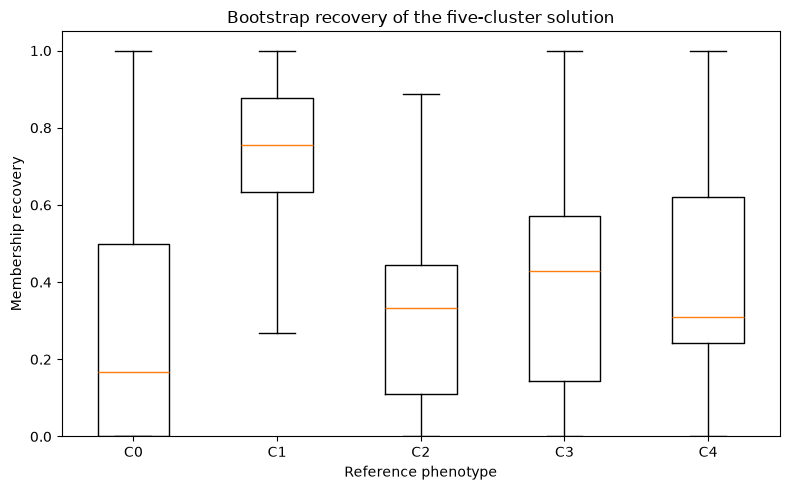

In [10]:
# ============================================================
# 8. Cluster-specific recovery distributions
# ============================================================

recovery_by_cluster = [
    recovery_df.loc[
        recovery_df["cluster"] == c,
        "recovery"
    ].to_numpy()
    for c in range(5)
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    recovery_by_cluster,
    tick_labels=["C0", "C1", "C2", "C3", "C4"],
    showfliers=False
)

plt.ylabel("Membership recovery")
plt.xlabel("Reference phenotype")
plt.title(
    "Bootstrap recovery of the five-cluster solution"
)

plt.ylim(0, 1.05)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "gmm_k5_cluster_recovery.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
## Bootstrap stability

The stability of the retained five-component GMM was evaluated using
500 bootstrap resamples of the 92-participant baseline clustering sample.

For each bootstrap iteration, a five-component full-covariance GMM was
estimated on a participant-level sample drawn with replacement. The
bootstrap-fitted model was then applied to the original 92 participants,
allowing its partition to be compared with the reference five-component
solution using the adjusted Rand index (ARI).

All 500 bootstrap models converged. However, agreement with the reference
partition was low (mean ARI = .166; median = .158; 5th–95th percentile =
.040–.310). Bootstrap-derived solutions also frequently contained very
small components (median minimum predicted component size = 4).

After permutation matching of component labels, membership recovery was
highest for C1 (mean = .726; median = .756). Recovery was substantially
lower for C0 (mean = .260), C2 (.286), C3 (.412), and C4 (.423).

These findings indicate that the retained five-component solution is
sensitive to sampling variation and should not be interpreted as a stable
or uniquely determined latent taxonomy. Accordingly, the five phenotypes
are treated as exploratory, sample-specific data-driven profiles.
Subsequent clinical and neuroimaging findings characterize differences
associated with this particular solution rather than establishing
replicable transdiagnostic subtypes.